# 1854 Cholera Basic: dots, counts and centres

**PHI outbreak investigations · 20–30 minutes · original browser companion**

An original browser-safe companion to PHI-Case-Studies: explore six invented locations, distinguish zero from missingness, and compare listed-location and death-weighted centres before making a historical claim.

**Learning question:** How can two centres summarize the same dots differently, and what do neither of them establish?

**Data status:** original synthetic teaching fixture; no historical measurements, real patient records, source map or external data requests. This bounded companion runs with standard-library Python and IPython in the atlas Lab. Linked source courses have their own rights and runtimes.


## Predict before running

Before trusting a map, decide what each mark counts. The six invented rows contain IDs, x/y coordinates in arbitrary planar units and fictional death counts. Five locations have positive counts; B3 has an observed zero, not a missing record. A listed-location centre gives every row equal weight. A death-weighted centre gives each fictional death equal weight. Predict which centre will lie nearer the A locations. No source records or actual Soho coordinates are used.

Write a prediction and an assumption. Run cells in order with **Shift+Enter** or **Run → Run All Cells**. The first code cell supplies local SVG display helpers; the next performs the calculation. Every figure has a title/description and printed values as a text alternative. Allow up to 60 seconds per cell on first runtime load; the fixture calculation normally takes seconds and needs no installs, account or credentials.


In [1]:
from IPython.display import SVG, display
from html import escape

def svg(body, title, description, width=760, height=330):
    label = escape(title, quote=True)
    display(SVG(f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" role="img" aria-label="{label}"><title>{escape(title)}</title><desc>{escape(description)}</desc><rect width="100%" height="100%" fill="#f5f5ef" rx="12"/>{body}</svg>'))

def bars(values, title, unit):
    print(title + ' | ' + unit + ':', {k:round(v,3) for k,v in values.items()})
    n = len(values)
    height = max(250, 82 + n*36)
    maximum = max(max(values.values()), 1)
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18" fill="#123c45">{escape(title)}</text>'
    for i,(key,value) in enumerate(values.items()):
        y=58+i*36
        body += f'<text x="22" y="{y+17}" font-family="sans-serif" font-size="13">{escape(str(key))}</text><rect x="205" y="{y}" width="{max(0,value)/maximum*440:.2f}" height="23" rx="3" fill="#16756b"/><text x="{213+max(0,value)/maximum*440:.2f}" y="{y+17}" font-family="sans-serif" font-size="13">{value:.2f}</text>'
    body += f'<text x="205" y="{height-15}" font-family="sans-serif" font-size="12">zero baseline · {escape(unit)}</text>'
    svg(body, title, 'Values are printed as a text alternative; consult the chart title for data status.', height=height)

def grid(values, columns, title):
    print(title + ':', [round(v,3) for v in values])
    maximum = max(max(values),1)
    size = 54
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text>'
    for i,v in enumerate(values):
        x=25+(i%columns)*size; y=52+(i//columns)*size
        light=92-50*v/maximum
        body += f'<rect x="{x}" y="{y}" width="50" height="50" fill="hsl(169,45%,{light:.1f}%)" stroke="#123c45"/><text x="{x+25}" y="{y+29}" text-anchor="middle" font-family="sans-serif" font-size="14" fill="#061c21">{v:.1f}</text>'
    svg(body,title,'Synthetic grid with values printed in each cell; no actual boundaries.',height=max(220,70+((len(values)+columns-1)//columns)*size))

def lines(series, title, xunit, yunit):
    print(title + ':', {k:[round(v,3) for v in vs] for k,vs in series.items()})
    maximum=max(max(vs) for vs in series.values()) or 1
    body=f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text><path d="M55 55V265H710" fill="none" stroke="#123c45"/>'
    for j,(name,vs) in enumerate(series.items()):
        color=['#16756b','#a34712','#41449c'][j%3]
        pts=' '.join(f'{55+i*650/max(1,len(vs)-1):.1f},{265-v*200/maximum:.1f}' for i,v in enumerate(vs))
        body+=f'<polyline points="{pts}" fill="none" stroke="{color}" stroke-width="3"/><text x="{60+j*220}" y="310" font-family="sans-serif" font-size="13" fill="{color}">{escape(name)}</text>'
    body+=f'<text x="55" y="288" font-family="sans-serif" font-size="12">{escape(xunit)} → · {escape(yunit)} ↑ · y starts at zero</text>'
    svg(body,title,'Synthetic series; printed values are the text alternative.')


Invented rows (id, x, y, fictional deaths): [('A1', 1, 1, 6), ('A2', 1, 3, 4), ('A3', 3, 2, 2), ('B1', 7, 1, 1), ('B2', 7, 3, 1), ('B3', 9, 2, 0)]
Listed locations: 6; positive-death locations: 5/6; fictional deaths: 14
Unweighted listed-location centre, planar units: (4.666667, 2.000000)
Death-weighted centre, planar units: (2.142857, 1.857143)
No at-risk population denominator: counts and centres are not attack rates, pump use or causal evidence.


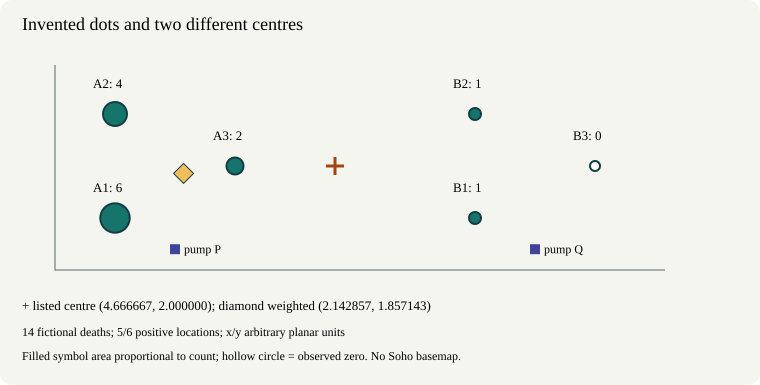

In [2]:
from math import sqrt

# Six invented locations; arbitrary planar units, fictional death counts.
rows = [('A1', 1, 1, 6), ('A2', 1, 3, 4), ('A3', 3, 2, 2),
        ('B1', 7, 1, 1), ('B2', 7, 3, 1), ('B3', 9, 2, 0)]
pumps = {'P': (2, 0.4), 'Q': (8, 0.4)}  # illustrative only; no use observations

def centres(records):
    total = sum(row[3] for row in records)
    unweighted = tuple(sum(row[i] for row in records) / len(records) for i in (1, 2))
    weighted = (tuple(sum(row[i] * row[3] for row in records) / total for i in (1, 2))
                if total else None)
    return total, unweighted, weighted

total, unweighted, weighted = centres(rows)
positive = sum(row[3] > 0 for row in rows)
def point_label(value):
    return 'unknown' if value is None else f'({value[0]:.6f}, {value[1]:.6f})'
print('Invented rows (id, x, y, fictional deaths):', rows)
print(f'Listed locations: {len(rows)}; positive-death locations: {positive}/{len(rows)}; fictional deaths: {total}')
print('Unweighted listed-location centre, planar units:', point_label(unweighted))
print('Death-weighted centre, planar units:', point_label(weighted))
print('No at-risk population denominator: counts and centres are not attack rates, pump use or causal evidence.')

def project(x, y):
    return 55 + x * 60, 270 - y * 52
body = '<text x="22" y="30" font-size="18">Invented dots and two different centres</text>'
body += '<path d="M55 65V270H665" fill="none" stroke="#52676b"/>'
for identifier, x, y, count in rows:
    px, py = project(x, y)
    radius = sqrt(count) * 6 if count else 5
    fill = '#16756b' if count else '#ffffff'
    body += f'<circle cx="{px}" cy="{py}" r="{radius:.3f}" fill="{fill}" stroke="#123c45" stroke-width="2"/>'
    body += f'<text x="{px-22}" y="{py-26}" font-size="13">{escape(identifier)}: {count}</text>'
for identifier, (x, y) in pumps.items():
    px, py = project(x, y)
    body += f'<rect x="{px-5}" y="{py-5}" width="10" height="10" fill="#41449c"/><text x="{px+9}" y="{py+4}" font-size="12">pump {escape(identifier)}</text>'
ux, uy = project(*unweighted)
body += f'<path d="M{ux-9} {uy}H{ux+9}M{ux} {uy-9}V{uy+9}" stroke="#a34712" stroke-width="3"/>'
if weighted is not None:
    wx, wy = project(*weighted)
    body += f'<path d="M{wx} {wy-10}L{wx+10} {wy}L{wx} {wy+10}L{wx-10} {wy}Z" fill="#f3bd5c" stroke="#123c45"/>'
body += f'<text x="22" y="310" font-size="13">+ listed centre {escape(point_label(unweighted))}; diamond weighted {escape(point_label(weighted))}</text>'
body += f'<text x="22" y="336" font-size="12">{total} fictional deaths; {positive}/{len(rows)} positive locations; x/y arbitrary planar units</text>'
body += '<text x="22" y="360" font-size="12">Filled symbol area proportional to count; hollow circle = observed zero. No Soho basemap.</text>'
description = f'{len(rows)} invented locations, {positive} positive, {total} fictional deaths. Listed centre {point_label(unweighted)}; weighted centre {point_label(weighted)}. ' + '; '.join(f'{name}: {count}' for name, x, y, count in rows)
svg(body, 'Synthetic Cholera Basic: dots and centres', description, height=385)


## Interpret the result

The default has 6 listed locations, 5 positive-death locations and 14 fictional deaths. The listed-location centre is (28/6, 12/6) = (4.666667, 2). The weighted centre is (30/14, 26/14) = (2.142857, 1.857143). The SVG gives positive circles area proportional to count and retains the hollow observed-zero circle. The plus and diamond answer different summary questions. Neither centre identifies who used a pump, an exposure, an infection source or a causal effect. Without an at-risk population denominator these are counts, not attack rates.

## Change one thing

Change only `('B3', 9, 2, 0)` to `('B3', 9, 2, 14)`. Predict, then rerun: 28 fictional deaths and weighted centre (156/28, 54/28), while the listed-location centre stays fixed. Read the text and look for the shifted diamond. Next set every count to zero: the weighted centre must say **unknown**, and every location must remain visible. Restore defaults before comparing with a partner. Explain why adding a population field would require a new rate calculation rather than renaming a count.

Save your edited experiment with **File → Save and Export Notebook As → Notebook** or the file browser's Download command. Browser storage belongs to this browser/profile; it is not a GitHub commit or a shared patient database. Restart the kernel and Run All to check your saved version.


## Put the method in context

Snow's 1854 investigation is compelling because maps were part of a wider inquiry into water and households. His water hypothesis preceded the famous map, and Whitehead, households and local officials contributed evidence. Attacks were already declining when the handle was removed on 8 September; a vivid before/after story does not identify a counterfactual effect. Read the linked primary account and historical reassessment below, and distinguish historical evidence from our six-row experiment. The source's first lesson develops tables/layers and an information value cycle; its second examines a weighted centre. This companion makes those two questions small enough to inspect in one browser session.


## 1854 Cholera Basic: dots, counts and centres: inspected source notebooks

**Creators:** PHI-Case-Studies and contributors; the Cholera notebooks list contact credits for Herman Tolentino, Jan MacGregor, James Tobias and Zhanar Haimovich. Contacts do not establish sole authorship.

**Repository:** [PHI-Case-Studies/Jupyterlite-1854-Cholera-Basic](https://github.com/PHI-Case-Studies/Jupyterlite-1854-Cholera-Basic). [Reviewed README](https://github.com/PHI-Case-Studies/Jupyterlite-1854-Cholera-Basic/blob/476f6dd5a8430e6eb823e79614fda1d7e12a78fb/README.md), full commit `476f6dd5a8430e6eb823e79614fda1d7e12a78fb`, branch `main`, inspected 2026-11-02.

The source supplies a published JupyterLite course. Its pandas/Folium maps and external tiles have separate runtime and attribution requirements; their execution is not certified by entry checks.

**Source rights:** Root LICENSE: GNU GPLv3.

| Inspected source file | What the source teaches |
|---|---|
| [NB01-Cholera-Case-Study-Folium-Map-Part-1.ipynb](https://github.com/PHI-Case-Studies/Jupyterlite-1854-Cholera-Basic/blob/476f6dd5a8430e6eb823e79614fda1d7e12a78fb/NB01-Cholera-Case-Study-Folium-Map-Part-1.ipynb) | Tables, deaths/pumps, Folium layers and the information value cycle |
| [NB02-Cholera-Case-Study-Folium-Map-Part-2.ipynb](https://github.com/PHI-Case-Studies/Jupyterlite-1854-Cholera-Basic/blob/476f6dd5a8430e6eb823e79614fda1d7e12a78fb/NB02-Cholera-Case-Study-Folium-Map-Part-2.ipynb) | Death-weighted mean centre and careful map interpretation |

[Root license at the inspected commit](https://github.com/PHI-Case-Studies/Jupyterlite-1854-Cholera-Basic/blob/476f6dd5a8430e6eb823e79614fda1d7e12a78fb/LICENSE).

The [published contents manifest](https://phi-case-studies.github.io/Jupyterlite-1854-Cholera-Basic/api/contents/all.json) was inspected 2026-11-02. The [existing source audit](https://jltobias.github.io/JupyterLite-Learning-Atlas/catalog/launch-checks.json) records its dated URL, source commit, confirmed course notebook basenames and canonical-JSON SHA-256 under `manifest_evidence`, separate from launch rows. This confirms filenames, not source execution or provider behavior. The reviewed Basic README supplies the course root; the manifest separately confirms its two root notebook filenames.


## Source launch resources and runtime limits

- [Open source course](https://phi-case-studies.github.io/Jupyterlite-1854-Cholera-Basic) — README-documented course root; separate source runtime. **HTTP 200 - entry only; checked 2026-11-02.**
- [Open source Lab](https://phi-case-studies.github.io/Jupyterlite-1854-Cholera-Basic/lab/index.html) — Published source Lab entry; execution and provider behavior not certified. **HTTP 200 - entry only; checked 2026-11-02.**
- [Run source lesson 1](https://phi-case-studies.github.io/Jupyterlite-1854-Cholera-Basic/lab/index.html?path=NB01-Cholera-Case-Study-Folium-Map-Part-1.ipynb) — Exact root notebook path confirmed in published manifest; source execution not certified. **HTTP 200 - entry only; checked 2026-11-02.**
- [Run source lesson 2](https://phi-case-studies.github.io/Jupyterlite-1854-Cholera-Basic/lab/index.html?path=NB02-Cholera-Case-Study-Folium-Map-Part-2.ipynb) — Exact root notebook path confirmed in published manifest; source execution not certified. **HTTP 200 - entry only; checked 2026-11-02.**

These dated GET checks establish entry reachability only. The Basic/Advanced1 notebook filenames were also present in published manifests; no source execution, widget, tile/provider behavior or Binder session is certified. No Binder build is triggered by these atlas activities. Source continuation may require packages, networking and provider terms absent from the default atlas runtime.


## Sources, attribution and use

- **Snow, John (1855).** *On the Mode of Communication of Cholera*, 2nd ed., London: John Churchill, pp. 38–55. [Primary transcription and map context, UCLA](https://epi-snow.ph.ucla.edu/Stream2_BSPoutbreak_a.html). Credit Charles Frederick Cheffins for historical maps drawn for Snow, and Ralph R. Frerichs and contributors for UCLA archive/curation. Historical maps are linked, never reproduced.
- **Brody, H.; Rip, M. R.; Vinten-Johansen, P.; Paneth, N.; Rachman, S. (2000).** *Map-making and myth-making in Broad Street: the London cholera epidemic, 1854.* Lancet **356**(9223), 64–68. [DOI](https://doi.org/10.1016/S0140-6736(00)02442-9), [author reprint](https://epi-snow.ph.ucla.edu/Stream2_BSPoutbreak_f.html). Snow's water hypothesis preceded the famous map; a map alone did not establish an intervention effect.
- **UCLA Department of Epidemiology, Ralph R. Frerichs and contributors.** [Historical investigation](https://epi-snow.ph.ucla.edu/Stream2_BSPoutbreak_d.html) and [Henry Whitehead context](https://epi-snow.ph.ucla.edu/Stream2_BSPoutbreak_e.html). Household inquiries, Whitehead and local officials contributed; attacks were already declining before the pump handle was removed on 8 September 1854.
- **CDC (2004).** *150th Anniversary of John Snow and the Pump Handle.* MMWR **53**(34), 783. [Historical overview](https://www.cdc.gov/mmwr/preview/mmwrhtml/mm5334a1.htm). A retrospective account is not a randomized counterfactual comparison.
- **World Health Organization (29 September 2026).** [*Cholera* fact sheet](https://www.who.int/news-room/fact-sheets/detail/cholera). Contaminated food/water, safe water, sanitation and community work provide context; this activity supplies no burden or treatment estimate.

All summaries, code, synthetic fixtures and SVGs here are newly authored: MIT executable code; CC BY 4.0 narrative, fixtures and figures, James L. Tobias and JupyterLite Learning Atlas contributors (2026). No source code/prose/data/imagery, patient records, pickles, saved graphs or map tiles are copied. Source rights remain with their creators; public access and shared contributors imply no blanket relicensing or endorsement.

[Central references](../../references.ipynb) · [Visual provenance](../../visual-provenance.ipynb)


## Continue the investigation

Basic → Advanced1 → Advanced2 → MDR-TB is the suggested order.

[1854 Cholera Advanced1: routes and reachable nodes](../cholera-1854-advanced-1/index.ipynb) · [1854 Cholera Advanced2: nearest sites, ties and buildings](../cholera-1854-advanced-2/index.ipynb) · [2005 MDR-TB Thailand: contact evidence and unknown results](../mdr-tb-thailand-2005/index.ipynb)

[Browser Python](../../foundations/browser-python.ipynb) · [Spatial thinking](../../foundations/spatial-thinking.ipynb) · [Global-health synthesis](../../synthesis/global-health.ipynb) · [Learning routes](../../index.ipynb)
